In [1]:
## Libraries 

from IPython.display import HTML, display

import networkx as nx
import matplotlib.pyplot as plt

<div> 
    <h2 style="text-align: center> CONTENTS</h2>
</div>

<div> 
    <h2>CONTENTS</h2>
    <ol>
    <li>Introduction to Network Theory</li>
    <li> Regular Network</li>
    <li> Network Metrics </li><ol>
    <li> Degree Distribution</li>
        <li> Shortest Path Length and its matrix representation</li>
        <li>Average path length and diameter</li>
        <li>Global(Transitivity) and Local Clustering Coefficients</li>
</div>


<div style="text-align: center !important; font-size:24px !important">
Introduction to the Network Theory
</div>

<div>
The history of graph theory in mathematical problem-solving dates back to 1739. Swiss-born mathematician Leonhard Euler played a role in the birth of graph theory. During his time in St. Petersburg, Euler encountered a famous question among the locals: Could one visit all the islands using each bridge exactly once? This problem involved four islands connected by seven bridges.
</div>

<figure style="text-align: center; float: right; margin-right: 15px">
    <img src="../images/bridge.jpg" alt="Description" width="400";>
    <figcaption><b>Figure 1:</b> Könisberg Bridge </figcaption>
</figure>

<div>
Euler reformulated the question as a graphical problem. He assigned uppercase letters $A, B, C$ and $D$ to the islands (referred to as vertices or nodes) and lowercase letters $a, b, c, d, e, f$ and $g$ to the bridges (referred to as edges or links). In $1736$, he proposed a solution, proving that there was no way to traverse all islands while crossing each bridge only once. 
Euler’s solution was both simple and elegant: he counted the number of bridges connected to each island. For example, there were three bridges connecting islands B (or C) to others. This meant that the degrees of nodes $A, B, C,$ and $D$ were $5, 3, 3,$ and $3$, respectively. Although it might have been possible for only two nodes with odd degrees (representing the start and end points) to visit every island by crossing each bridge once, the question at hand involved four nodes with odd degrees. Therefore, there is no way to visit all the islands by crossing the bridges once.
</div>

<div> <b>Definition (Graph):</b> A graph $G$ is an ordered triple $(V(G), E(G), \psi_{G})$ consisting of a non-empty set $V(G)$ of vertices, a set $E(G)$, disjoint from $V(G)$, of edges, and an incidence function $\psi_{G}$ that associates with each edge of $G$ an unordered pair of (not necessarily distinct) vertices of $G$. If $e$ is an edge and $u$ and $v$ are vertices such that $\psi_{G} = uv$, then $e$ is said to join $u$ and $v$; the vertices $u$ and $v$ are called the ends of $e$.
</div> 



$\begin{align*}
G =& (V(G),E(G),ψG), \text{where}\\
& V(G) = {A,B,C,D}, \\
& E(G) = {a,b,c,d,e,f,g},\\
& ψG(a) = AB,\psi G(b) = AB,\psi G(c) = AC,\psi G(d) = AC,ψG(e) = AD, \psi G(f) = BD,\psi G(g) = CD.
\end{align*}$

<div> The terms “Graph” and “Network” that they are commonly used interchangeably in the scientific literature. However, the difference lies in that the graph refers to the schematic visualisation to solve a mathematical problem, whereas the network refers to graphical representation of real-life problem such as transportation maps, social interactions, protein-protein interactions, etc. Despite their close relationship, we shall henceforth refer to them as “network” and their components, vertices and edges, as “nodes” and “links”, respectively.</div>


### 1. Regular Network 

<div>
If all the $n$ nodes of a network $N$ has equal degree ($d$), it is called "Regular Network". To be able to build a regular network, the total degree ($\sum_{1}^{n}d_{i}$) should be equal to an even number following that $n\times d = \text{even number}$. Obviously, $n>d$ since a node can connect $(n-1)$ nodes at maximum.
</div>

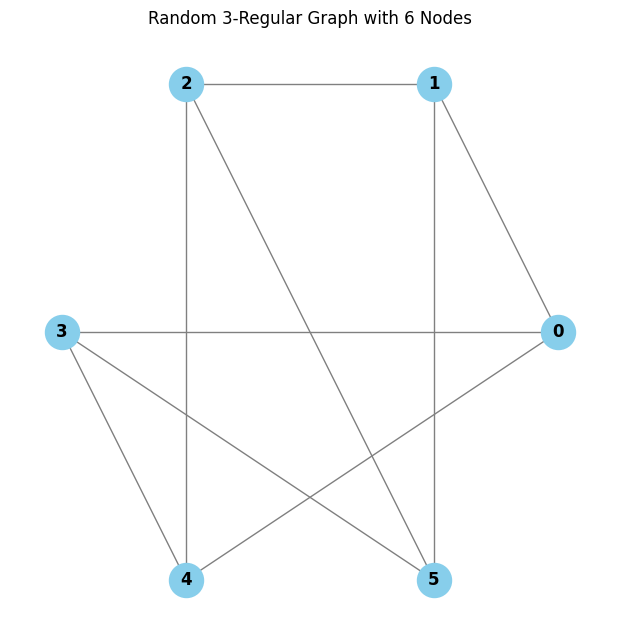

In [2]:

# Parameters: n nodes, each with degree d
d = 3   # 3-regular (cubic graph)
n = 6  # 10 nodes (n * d = 30, which is even)

# Generate the graph
G = nx.random_regular_graph(d, n, seed=42)

# Visualize the graph
plt.figure(figsize=(6, 6))
pos = nx.circular_layout(G)
nx.draw(
    G, 
    pos, 
    with_labels=True, 
    node_color="skyblue", 
    node_size=600, 
    edge_color="gray", 
    font_weight="bold"
)
plt.title(f"Random {d}-Regular Graph with {n} Nodes")
plt.show()

In [3]:
## Adjacency matrix as 2-d numpy array

import numpy as np
A = nx.to_numpy_array(G, dtype=int)
print(A)
print(sum(sum(A))) ## Total number of degrees equals to nxd.

[[0 1 0 1 1 0]
 [1 0 1 0 0 1]
 [0 1 0 0 1 1]
 [1 0 0 0 1 1]
 [1 0 1 1 0 0]
 [0 1 1 1 0 0]]
18


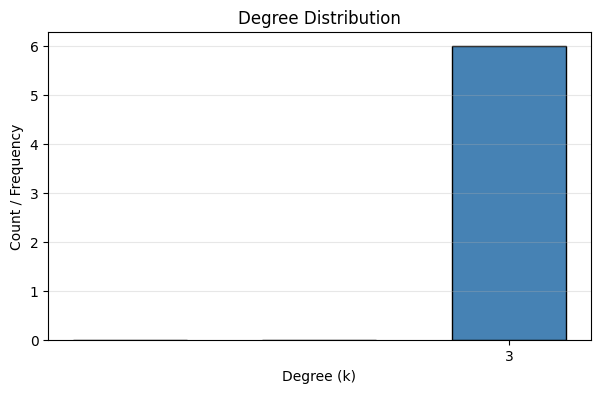

In [4]:
## Degree Distribution

degrees = [d for n, d in G.degree()]

# 2. Plot the degree distribution histogram
plt.figure(figsize=(7, 4))
plt.hist(
    degrees, 
    bins = range(min(degrees)-2, max(degrees)+2), 
    align='left', 
    rwidth=0.6, 
    color='steelblue', 
    edgecolor='black'
)

plt.title("Degree Distribution")
plt.xlabel("Degree (k)")
plt.ylabel("Count / Frequency")
plt.xticks(range(min(degrees), max(degrees) + 1))
plt.grid(axis='y', alpha=0.3)
plt.show()

<div>
<h3 style="text-align: center;"> Network Metrics </h3>
<p><b> Path Length: </b> A path in a network is defined as the set of links that connect any two nodes. For instance,
$P_1 = 1 \to 3  \to 2 \to 4$ is a path between nodes $1$ and $4$ traversing along nodes $3$ and $2$. The path length is the number of links traversed along the path so, the path length is $\ |P_1|= 3$ for this path.</p> 
    
<b>Shortest Path Matrix ($\mathcal{D}$):</b> For the adjaceny matrix $A$, $A^{k}$ is the matrix whose entries give the number of $k$-length between any 2 nodes such that:
$$\begin{align*}
    A_{ij} &= \text{the number of $1$-length path between nodes $i$ and $j$.}\\
    A^{2}_{ij} &= \text{the number of $2$-length path between nodes $i$ and $j$.}\\
    \vdots \\
    A^{n-1}_{ij} &= \text{the number of $(n-1)$-length path between nodes $i$ and $j$, the possible maximum shortest length 
for $N$ with $n$ nodes.}
\end{align*}$$
The algorithm below, calculates the power of adjacency matrix until all entries become bigger than $1$ except diagonals (for more effective algorithms for large networks visit the <a href="https://networkx.org/documentation/stable/reference/algorithms/shortest_paths.html">documentation</a>.</div>

<div class="algorithm-box">
  <div class="alg-header">
    <span class="alg-title">Algorithm:</span> All-Pairs Shortest Paths via Matrix Powers
  </div>

  <div class="alg-io">
    <div><strong>Input:</strong> Adjacency matrix $\mathbf{A} \in \{0, 1\}^{n \times n}$ of an unweighted graph</div>
    <div><strong>Output:</strong> Distance matrix $\mathbf{D} \in (\mathbb{R} \cup \{\infty\})^{n \times n}$</div>
  </div>

  <ol class="alg-body">
    <li>$n \gets \text{number of rows in } \mathbf{A}$</li>
    <li>Initialize $\mathbf{D} \in \mathbb{R}^{n \times n}$ with all entries set to $\infty$</li>
    <li>$\mathbf{D}_{ii} \gets 0 \quad \text{for all } i \in \{1, \dots, n\}$</li>
    <li>$\mathbf{A}_k \gets \mathbf{I}_n \quad$ <span class="comment">/* Identity matrix of size $n \times n$ */</span></li>
    <li>
      <span class="kw">for</span> $k \gets 1$ <span class="kw">to</span> $n - 1$ <span class="kw">do</span>
      <div class="alg-block">
        <div>$\mathbf{A}_k \gets \mathbf{A}_k \times \mathbf{A} \quad$ <span class="comment">/* Compute $\mathbf{A}^k$ */</span></div>
        <div>
          <span class="kw">for each</span> pair $(i, j)$ <span class="kw">where</span> $\mathbf{D}_{ij} = \infty$ <span class="kw">and</span> $(\mathbf{A}_k)_{ij} > 0$ <span class="kw">do</span>
          <div class="alg-block">
            <div>$\mathbf{D}_{ij} \gets k$</div>
          </div>
          <span class="kw">end for</span>
        </div>
        <div>
          <span class="kw">if</span> no entry in $\mathbf{D}$ is equal to $\infty$ <span class="kw">then</span>
          <div class="alg-block">
            <div><span class="kw">break</span> <span class="comment">/* All pairwise distances determined */</span></div>
          </div>
          <span class="kw">end if</span>
        </div>
      </div>
      <span class="kw">end for</span>
    </li>
    <li><span class="kw">return</span> $\mathbf{D}$</li>
  </ol>
  <div class="alg-footer"></div>
</div>

<style>
  .algorithm-box {
    font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, Arial, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    max-width: 650px;
    margin: 20px auto;
    border-top: 2px solid #222;
    border-bottom: 2px solid #222;
    padding: 6px 0;
    color: #111;
  }

  .alg-header {
    font-size: 15px;
    padding-bottom: 6px;
    border-bottom: 1px solid #222;
    margin-bottom: 8px;
  }

  .alg-title {
    font-weight: bold;
  }

  .alg-io {
    padding-bottom: 8px;
    border-bottom: 1px solid #222;
    margin-bottom: 8px;
  }

  .alg-body {
    margin: 0;
    padding-left: 32px;
  }

  .alg-body li {
    padding-left: 6px;
    margin-bottom: 3px;
  }

  .alg-block {
    margin-left: 18px;
    border-left: 1px solid #ddd;
    padding-left: 8px;
    margin-top: 2px;
    margin-bottom: 2px;
  }

  .kw {
    font-weight: bold;
  }

  .comment {
    color: #666;
    font-style: italic;
    font-size: 13px;
  }
</style>



<div>
    <p><b>Average Shortest Path Length:</b> $\bar{d}$, is the mean of the shortest path lengths across the network,</p>
        \[ \bar{d} = \frac{1}{n (n-1)}\sum_{i \neq j}^{n}\mathcal{D}_{ij} \]
    <p><b> Diameter:</b> The diameter, $R$, of a network is the maximum of the shortest path lengths across all
pairs of nodes so, the greatest entry in matrix, $\mathcal{D}_{ij}$.
</div>

In [5]:

# A: 2D numpy array (adjacency matrix)
n = A.shape[0]

# Initialize distance matrix
D = np.full((n, n), np.inf)
np.fill_diagonal(D, 0)

# Matrix power iteration
A_k = np.eye(n, dtype=int)
for k in range(1, n):
    A_k = A_k @ A
    # Find pairs not yet visited that have a path of length k
    unvisited_mask = (D == np.inf) & (A_k > 0)
    D[unvisited_mask] = k
    
    # Early break if all distances have been resolved
    if not np.isinf(D).any():
        break

print("Shortest Path Length Matrix D = \n", D)
print("Average shortest Path = ",round(np.sum(sum(D))/(n*(n-1)),2))
print("Diameter = ", int(np.max(D)))

Shortest Path Length Matrix D = 
 [[0. 1. 2. 1. 1. 2.]
 [1. 0. 1. 2. 2. 1.]
 [2. 1. 0. 2. 1. 1.]
 [1. 2. 2. 0. 1. 1.]
 [1. 2. 1. 1. 0. 2.]
 [2. 1. 1. 1. 2. 0.]]
Average shortest Path =  1.4
Diameter =  2


<div>
    <p><b>Clustering Coefficients </b></p>
    There are two types of clustering coefficients has been worked in the literature:
    <li> <b>The global clustering coefficient</b>, also known as <b>transitivity</b>, considers the number of connected triplets of nodes,
    \begin{align*}
        T &= \frac{\text{Number of Triangles}}{\text{Number of Triplets}} \\    
       \text{Number of triangles} &= \frac{1}{6} Tr(A) \\
       \text{Number of triples} &= \sum_{i}^{n}\binom{d_i}{2} = \frac{1}{2}\sum_{i}^{n}d(d-1), \text{where $n_i$ is the centred node in 3-length path} \\
    \end{align*}
    </li>
    <li><b>The local clustering coefficient</b> that considers the degree of the neighbours of a node, which was introduced to quantify the small-worldness of a network.
    $$C = \frac{1}{n}\sum_{i}^{n}C_{i},$$
    for individual node $i$ with degree $d_{i}>2$,
    $$C_{i} = \frac{2e_{i}}{d_{i}(d_{i}-1)},$$
    where $e_{i}$ is the number of links between the neighbours of node $i$, in other words, the number of triangles including the node $i$.
    </li>
<font color="red"> <b>NOTE:</b> </font> The formulas for transitivity and local clustering coefficient are pretty similar but the transitivity calculates the ratio of total number of triangles to total number of triples for whole network at once instead of how the local clustering coefficient computes it node by node.
</div>

In [6]:
A_2 = A@A
A_3 = A_2@A
print("1/6 of Trace of the matrix A^{3}, \n", A_3, "\n gives the number of triples (3-length path) whose start and end point is the same node (counted twice for each nodes)")


1/6 of Trace of the matrix A^{3}, 
 [[2 7 3 6 6 3]
 [7 2 6 3 3 6]
 [3 6 2 3 7 6]
 [6 3 3 2 6 7]
 [6 3 7 6 2 3]
 [3 6 6 7 3 2]] 
 gives the number of triples (3-length path) whose start and end point is the same node (counted twice for each nodes)


In [7]:
import networkx as nx

# Check if the graph is connected before computing distance metrics
if nx.is_connected(G):
    # 1. Average Shortest Path Length
    avg_path_length = nx.average_shortest_path_length(G)

    # 2. Diameter (longest shortest path between any pair of nodes)
    diameter = nx.diameter(G)
else:
    # If the graph has multiple components, compute on the largest connected component
    largest_cc = max(nx.connected_components(G), key=len)
    G_sub = G.subgraph(largest_cc)
    avg_path_length = nx.average_shortest_path_length(G_sub)
    diameter = nx.diameter(G_sub)
    print("Note: Graph is disconnected. Computed on the largest component.")

# 3. Clustering Coefficients
# Overall average clustering coefficient of the network
avg_clustering = nx.average_clustering(G)

# Global clustering coefficient (transitivity: ratio of 3x triangles to triads)
transitivity = nx.transitivity(G)

# Node-by-node clustering coefficients
local_clustering = nx.clustering(G)

# Display results
print(f"Average Path Length: {avg_path_length:.4f}")
print(f"Diameter: {diameter}")
print(f"Local Clustering (node-by-node): {local_clustering}")
print(f"Average Clustering Coefficient: {avg_clustering:.4f}")
print(f"Transitivity (Global Clustering): {transitivity:.4f}")


Average Path Length: 1.4000
Diameter: 2
Local Clustering (node-by-node): {0: 0.3333333333333333, 1: 0.3333333333333333, 2: 0.3333333333333333, 3: 0.3333333333333333, 4: 0.3333333333333333, 5: 0.3333333333333333}
Average Clustering Coefficient: 0.3333
Transitivity (Global Clustering): 0.3333
